In [2]:
#Fibonacci MLP vs Standard-MLP auf MNIST

In [3]:
## 1. Daten laden

In [10]:
# MNIST-Datensatz von OpenML (70.000 Bilder a 28x28 Pixel = 784 Features)
from sklearn.datasets import fetch_openml
import numpy as np

mnist = fetch_openml('mnist_784', version=1, as_frame=False)

X, y = mnist.data/255.0, mnist.target.astype(int)

np.savez('mnist_cache.npz', X=X, y=y)

In [11]:
import numpy as np
from sklearn.model_selection import train_test_split

data = np.load('mnist_cache.npz')
X, y = data['X'], data['y']

# IN_DIM = 784 (Anzahl Pixel pro Bild), OUT_DIM = 10 (Ziffern 0-9)
IN_DIM, OUT_DIM = X.shape[1], 10

# 80/20 Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)
print(X_train.shape, X_test.shape)

(56000, 784) (14000, 784)


In [12]:
## 2. Die Fibonacci Architektur

In [13]:
def fib_sequence(n):
    # klassische Fibonacci-Folge, aber ich starte mit 1,1 (Layer mit 0 Neuronen ergibt keinen Sinn)
    fibs = [1, 1]
    while len(fibs) < n:
        fibs.append(fibs[-1] + fibs[-2])
    return fibs[:n]

def standard_arch(in_dim, out_dim, K, base=128):
    sizes = [in_dim]
    for i in range(K):
        sizes.append(max(out_dim, int(base / (2**i))))
    sizes.append(out_dim)
    return sizes

def fibonacci_arch(in_dim, out_dim, K, scale=1):
    # Hidden-Layer-Größen kommen aus der Fibonacci-Folge
    fibs = fib_sequence(K)[::-1]  # absteigend, wie Standard-Netz
    sizes = [in_dim] + [f * scale for f in fibs] + [out_dim]
    return sizes

def n_params_of(sizes):
    # Anzahl trainierbarer Parameter: für jede Schicht Weights (sizes[i]*sizes[i+1]) + Biases (sizes[i+1])
    return sum(sizes[i]*sizes[i+1] + sizes[i+1] for i in range(len(sizes)-1))

def match_scale(in_dim, out_dim, K, target_params):
    # suche den scale-Faktor, bei dem das Fibonacci-Netz möglichst genau so viele Parameter hat wie das Standard-Netz
    best_scale, best_diff = 1, float("inf")
    for scale in range(1, 200):
        n = n_params_of(fibonacci_arch(in_dim, out_dim, K, scale=scale))
        diff = abs(n - target_params)
        if diff < best_diff:
            best_diff, best_scale = diff, scale
    return best_scale

print(standard_arch(IN_DIM, OUT_DIM, 3))
print(fibonacci_arch(IN_DIM, OUT_DIM, 3))

[784, 128, 64, 32, 10]
[784, 2, 1, 1, 10]


In [14]:
##3. MLP

In [15]:
class MLP:
    def __init__(self, sizes, seed=0):
        r = np.random.default_rng(seed)
        self.sizes = sizes
        # He-Initialisierung
        self.W = [r.normal(0, np.sqrt(2/sizes[i]), (sizes[i], sizes[i+1])) for i in range(len(sizes)-1)]
        self.b = [np.zeros(sizes[i+1]) for i in range(len(sizes)-1)]

    def n_params(self):
        # alle W und b Einträge zusammen
        return sum(w.size + b.size for w, b in zip(self.W, self.b))

    def forward(self, X):
        a = X
        self.acts = [a]  
        self.zs = []     
        for i in range(len(self.W)):
            z = a @ self.W[i] + self.b[i]   # lineare Transformation dieser Schicht
            self.zs.append(z)
            if i < len(self.W)-1:
                # in allen Hidden Layers: ReLU
                a = np.maximum(0, z)
            else:
                # letzte Schicht Softmax für Klassenwahrscheinlichkeiten
                # z.max abzeiehen für numerische Stabilität
                e = np.exp(z - z.max(axis=1, keepdims=True))
                a = e / e.sum(axis=1, keepdims=True)
            self.acts.append(a)
        return a

    def backward(self, X, y_onehot, lr):
        m = X.shape[0]  
        delta = self.acts[-1] - y_onehot
        for i in reversed(range(len(self.W))):
            a_prev = self.acts[i]
            dW = a_prev.T @ delta / m     # Gradient bzgl. der Gewichte über Batch
            db = delta.mean(axis=0)       # Gradient bzgl. der Biases
            if i > 0:
                # Fehler eine Schicht zurückpropagieren
                # 1. mit W^T multiplizieren 
                # 2. ReLU Ableitung anwenden 
                delta = (delta @ self.W[i].T) * (self.zs[i-1] > 0)
            # Gradient Descent Update
            self.W[i] -= lr * dW
            self.b[i] -= lr * db

    def train(self, X, y, epochs=20, lr=0.1, batch_size=32, n_classes=10, seed=0):
        y_onehot = np.eye(n_classes)[y]  
        n = X.shape[0]
        local_rng = np.random.default_rng(seed)
        for ep in range(epochs):
            idx = local_rng.permutation(n)  
            for start in range(0, n, batch_size):
                b_idx = idx[start:start+batch_size]
                self.forward(X[b_idx])
                self.backward(X[b_idx], y_onehot[b_idx], lr)

    def accuracy(self, X, y):
        preds = self.forward(X).argmax(axis=1)  # Klasse mit höchster Wahrscheinlichkeit auswählen
        return (preds == y).mean()

In [16]:
##4.Test: Standard vs Fibonacci für mehrere K

In [17]:
import pandas as pd

results = []
SEEDS = [0, 1, 2]   
EPOCHS = 20

for K in [2, 3, 4]:  # Hidden Layer
    std_sizes = standard_arch(IN_DIM, OUT_DIM, K)
    match_sc = match_scale(IN_DIM, OUT_DIM, K, n_params_of(std_sizes))
    fib_match_sizes = fibonacci_arch(IN_DIM, OUT_DIM, K, scale=match_sc)
    # zusätzlich ein kleines Fibonacci-Netz (scale=4)
    fib_small_sizes = fibonacci_arch(IN_DIM, OUT_DIM, K, scale=4)

    for name, sizes in [("standard", std_sizes),
                         ("fib_match", fib_match_sizes),
                         ("fib_small", fib_small_sizes)]:
        for seed in SEEDS:
            net = MLP(sizes, seed=seed)
            net.train(X_train, y_train, epochs=EPOCHS, seed=seed)
            acc = net.accuracy(X_test, y_test)
            results.append(dict(K=K, arch=name, sizes=str(sizes),
                                 params=net.n_params(), seed=seed, acc=acc))

df = pd.DataFrame(results)
summary = df.groupby(["K", "arch"]).agg(params=("params", "mean"),
                                          acc_mean=("acc", "mean"),
                                          acc_std=("acc", "std")).round(4)
summary

params  acc_mean  acc_std
K arch                                  
2 fib_match  108895.0    0.9806   0.0008
  fib_small    3210.0    0.8291   0.0252
  standard   109386.0    0.9797   0.0003
3 fib_match  111583.0    0.9791   0.0010
  fib_small    6386.0    0.8870   0.0053
  standard   111146.0    0.9751   0.0039
4 fib_match  112268.0    0.9752   0.0017
  fib_small    9630.0    0.9281   0.0025
  standard   111514.0    0.9762   0.0019

In [9]:
##5.Visualisierung

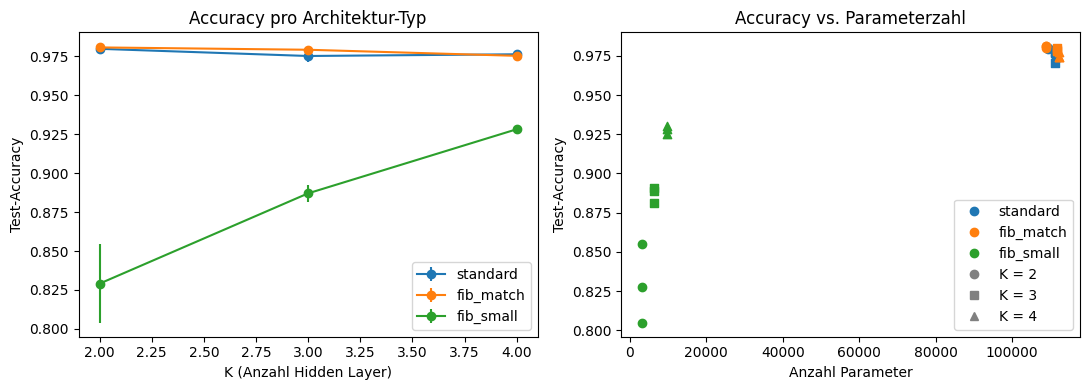

In [18]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

farben = {"standard": "tab:blue", "fib_match": "tab:orange", "fib_small": "tab:green"}
marker = {2: "o", 3: "s", 4: "^"}

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for arch in df["arch"].unique():
    sub = summary.xs(arch, level="arch")
    axes[0].errorbar(sub.index, sub["acc_mean"], yerr=sub["acc_std"],
                     label=arch, marker="o", color=farben[arch])
axes[0].set_xlabel("K (Anzahl Hidden Layer)")
axes[0].set_ylabel("Test-Accuracy")
axes[0].set_title("Accuracy pro Architektur-Typ")
axes[0].legend()

for arch in df["arch"].unique():
    for K in sorted(df["K"].unique()):
        sub = df[(df["arch"] == arch) & (df["K"] == K)]
        axes[1].scatter(sub["params"], sub["acc"], color=farben[arch], marker=marker[K])

legende_arch = [Line2D([0], [0], marker="o", linestyle="", color=farben[a], label=a)
                for a in farben]
legende_k = [Line2D([0], [0], marker=marker[k], linestyle="", color="grey", label=f"K = {k}")
             for k in marker]
axes[1].legend(handles=legende_arch + legende_k, loc="lower right")
axes[1].set_xlabel("Anzahl Parameter")
axes[1].set_ylabel("Test-Accuracy")
axes[1].set_title("Accuracy vs. Parameterzahl")

plt.tight_layout()
plt.savefig("fib_vs_standard.png", dpi=120)
plt.show()